# Mini Data Insight Dashboard
## Student Academic Performance & Dropout Risk

**Dataset:** https://www.kaggle.com/datasets/mohankrishnathalla/student-academic-performance-and-dropout-risk?select=student_dropout_risk_2026.csv

**Tools:** pandas, seaborn, plotly, Gradio

## Contents
1. Dataset
2. Exploratory Data Analysis (EDA)
3. Data Cleaning
4. Dashboard


# Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
file_path = "/content/student_dropout_risk_2026.csv"
df= pd.read_csv(file_path)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print("First 5 records:", df.head())

First 5 records:    person_id  age  gender nationality  first_generation  disability_status  \
0          1   23    Male      Brazil                 0                  0   
1          2   18   Other         USA                 1                  1   
2          3   24   Other         USA                 0                  0   
3          4   25  Female         USA                 0                  1   
4          5   15  Female      Canada                 0                  0   

  family_income_level  scholarship_holder  tuition_up_to_date  part_time_job  \
0                 Low                   1                   0              1   
1                High                   1                   1              0   
2                High                   0                   1              1   
3              Middle                   1                   1              0   
4                 Low                   1                   1              0   

   ...  library_visits_per_month 

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   person_id                     100000 non-null  int64  
 1   age                           100000 non-null  int64  
 2   gender                        100000 non-null  object 
 3   nationality                   100000 non-null  object 
 4   first_generation              100000 non-null  int64  
 5   disability_status             100000 non-null  int64  
 6   family_income_level           100000 non-null  object 
 7   scholarship_holder            100000 non-null  int64  
 8   tuition_up_to_date            100000 non-null  int64  
 9   part_time_job                 100000 non-null  int64  
 10  weekly_work_hours             100000 non-null  int64  
 11  course_type                   100000 non-null  object 
 12  study_mode                    100000 non-null

In [ ]:
df.shape

(100000, 34)

# EDA

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/Tuwaiq/data/student_dropout_risk_2026.csv"
df = pd.read_csv(file_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Missing values
Count of missing values in each column.

In [ ]:
missing = df.isna().sum()
print("Total missing values:", missing.sum())
print(missing[missing > 0] if missing.sum() else "No missing values in any column")

Total missing values: 0
No missing values in any column


### Basic statistics (mean, median, mode)
Summary statistics for numeric columns, and the most frequent value (mode) for every column.

In [ ]:
stats = df.describe().T[["mean", "50%", "std", "min", "max"]].rename(columns={"50%": "median"})
stats["mode"] = df[stats.index].mode().iloc[0]
print(stats.round(2))

                                  mean    median       std   min       max  \
person_id                     50000.50  50000.50  28867.66   1.0  100000.0   
age                              21.52     21.00      3.40  15.0      30.0   
first_generation                  0.42      0.00      0.49   0.0       1.0   
disability_status                 0.21      0.00      0.41   0.0       1.0   
scholarship_holder                0.59      1.00      0.49   0.0       1.0   
tuition_up_to_date                0.78      1.00      0.41   0.0       1.0   
part_time_job                     0.48      0.00      0.50   0.0       1.0   
weekly_work_hours                 8.74      0.00     10.23   0.0      40.0   
semester                          3.62      3.00      2.11   1.0       8.0   
international_student             0.18      0.00      0.38   0.0       1.0   
admission_grade                 133.15    133.10     28.26   5.5     200.0   
previous_qualification_grade    139.44    139.60     25.12  30.2

In [ ]:
# Mode and frequency for text columns
text_stats = df.select_dtypes("object").describe().T.rename(columns={"top": "mode"})
print(text_stats)

                      count unique       mode   freq
gender               100000      3     Female  50731
nationality          100000     15        USA  29979
family_income_level  100000      3     Middle  40213
course_type          100000      5       STEM  30141
study_mode           100000      3  Full-time  65096


### Prepare data for plotting
Create a plotting copy of the data (`viz`), define the target and column lists, and add helper functions.

In [ ]:
TARGET = "dropout"

# Plotting copy only; the original df is not changed (drops rows with a missing target, if any)
viz = df.dropna(subset=[TARGET]).copy()

# If the target is text (Yes/No), convert it to 0/1 inside viz only
if viz[TARGET].dtype == "object":
    viz[TARGET] = (viz[TARGET].astype(str).str.strip().str.lower()
                   .map({"yes": 1, "no": 0, "true": 1, "false": 0, "1": 1, "0": 0}))
viz[TARGET] = viz[TARGET].astype(int)

# Numeric columns (missing names are skipped automatically)
num_cols = [c for c in [
    "age", "admission_grade", "previous_qualification_grade",
    "gpa_semester_1", "gpa_semester_2", "attendance_rate",
    "assignments_submitted_rate", "lms_logins_per_week",
    "library_visits_per_month", "sleep_hours", "commute_time_mins",
    "stress_level", "satisfaction_score", "units_enrolled",
    "units_passed", "units_failed", "missed_deadlines",
    "weekly_work_hours",
] if c in viz.columns]

# Categorical columns
cat_cols = [c for c in [
    "gender", "nationality", "family_income_level", "study_mode", "semester",
    "course_type", "mental_health_support", "extracurricular_activities",
    "international_student", "first_generation", "disability_status",
    "scholarship_holder", "tuition_up_to_date", "part_time_job",
] if c in viz.columns]

# Overall dropout rate, used as a reference line in the category charts
overall_rate = viz[TARGET].mean()
print(f"Rows used: {len(viz):,} | Overall {TARGET} rate: {overall_rate:.1%}")
print("Numeric:", len(num_cols), "| Categorical:", len(cat_cols))


def make_grid(n, ncols=4, w=4.4, h=3.4):
    """Create a grid of subplots for n charts and hide the unused ones."""
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * w, nrows * h))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis("off")
    return fig, axes


def top_cats(col, n=10):
    """Return the n most frequent values of a categorical column."""
    return viz[col].value_counts().head(n).index

Rows used: 100,000 | Overall dropout rate: 32.0%
Numeric: 18 | Categorical: 14


### 1. Target distribution
How many students stayed vs dropped out.

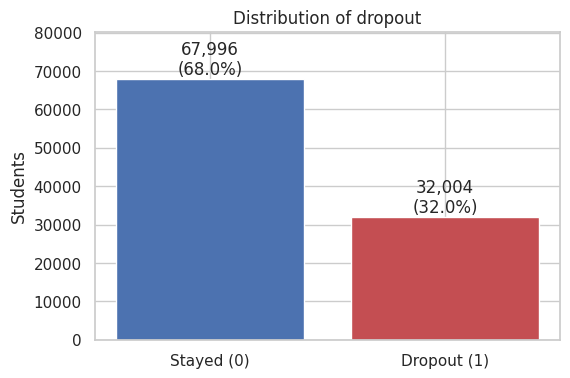

In [ ]:
counts = viz[TARGET].value_counts().sort_index()
labels = ["Stayed (0)", "Dropout (1)"]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, counts.values, color=["#4C72B0", "#C44E52"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / counts.sum():.1%})",
            ha="center", va="bottom")
ax.set_title(f"Distribution of {TARGET}")
ax.set_ylabel("Students")
ax.set_ylim(0, counts.max() * 1.18)
plt.show()

### 2. Numeric features: distributions
Histograms to see the shape of each numeric column.

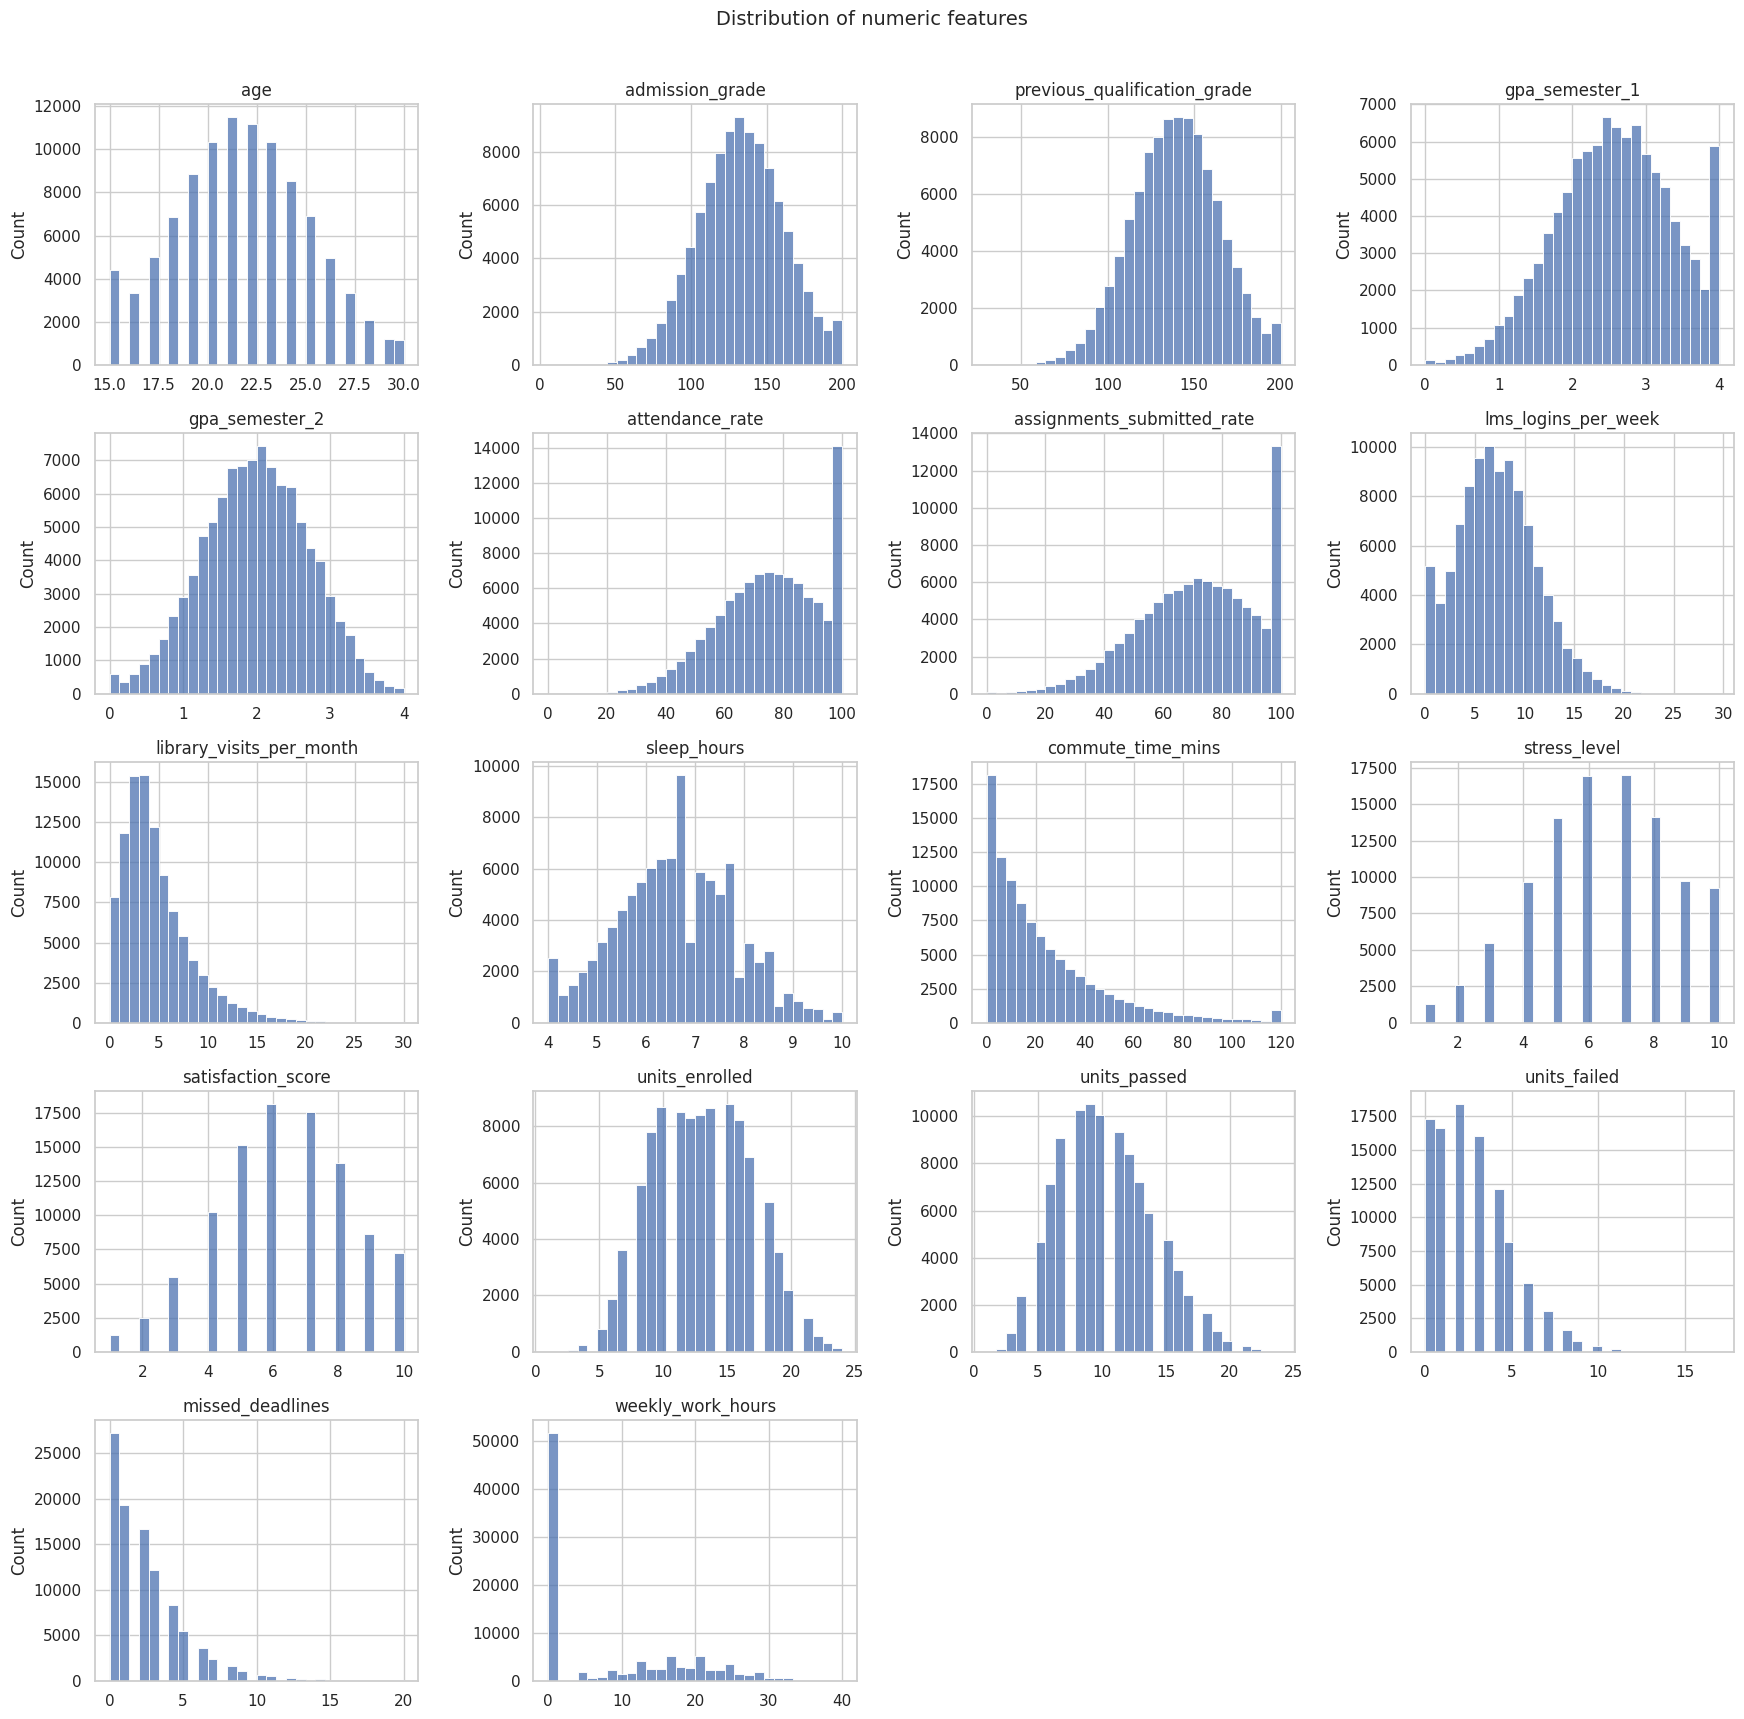

In [ ]:
fig, axes = make_grid(len(num_cols))
for ax, c in zip(axes, num_cols):
    sns.histplot(viz[c], bins=30, ax=ax, color="#4C72B0")
    ax.set_title(c)
    ax.set_xlabel("")
fig.suptitle("Distribution of numeric features", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Data quality checks
Before drawing conclusions, we check whether the data is consistent and whether values are capped at a limit.

In [ ]:
diff = viz["gpa_semester_2"] - viz["gpa_semester_1"]
print("GPA change (semester 2 - semester 1):")
print(diff.describe())

print()
print("Rows where passed + failed > enrolled:",
      (viz["units_passed"] + viz["units_failed"] > viz["units_enrolled"]).sum())
print("attendance_rate == 100:", (viz["attendance_rate"] == 100).sum())
print("sleep_hours == 4:", (viz["sleep_hours"] == 4).sum())

GPA change (semester 2 - semester 1):
count    100000.000000
mean         -0.587220
std           0.443886
min          -2.490000
25%          -0.890000
50%          -0.590000
75%          -0.290000
max           1.500000
dtype: float64

Rows where passed + failed > enrolled: 0
attendance_rate == 100: 10556
sleep_hours == 4: 2094


**Results:** GPA drops by 0.59 on average from semester 1 to semester 2. No row has more passed + failed units than enrolled units. Many values sit exactly at a limit (10,556 students with attendance = 100; 2,094 with sleep hours = 4).

### 3. Numeric features by dropout status
Boxplots comparing students who stayed (0) and dropped out (1). They also show outliers.

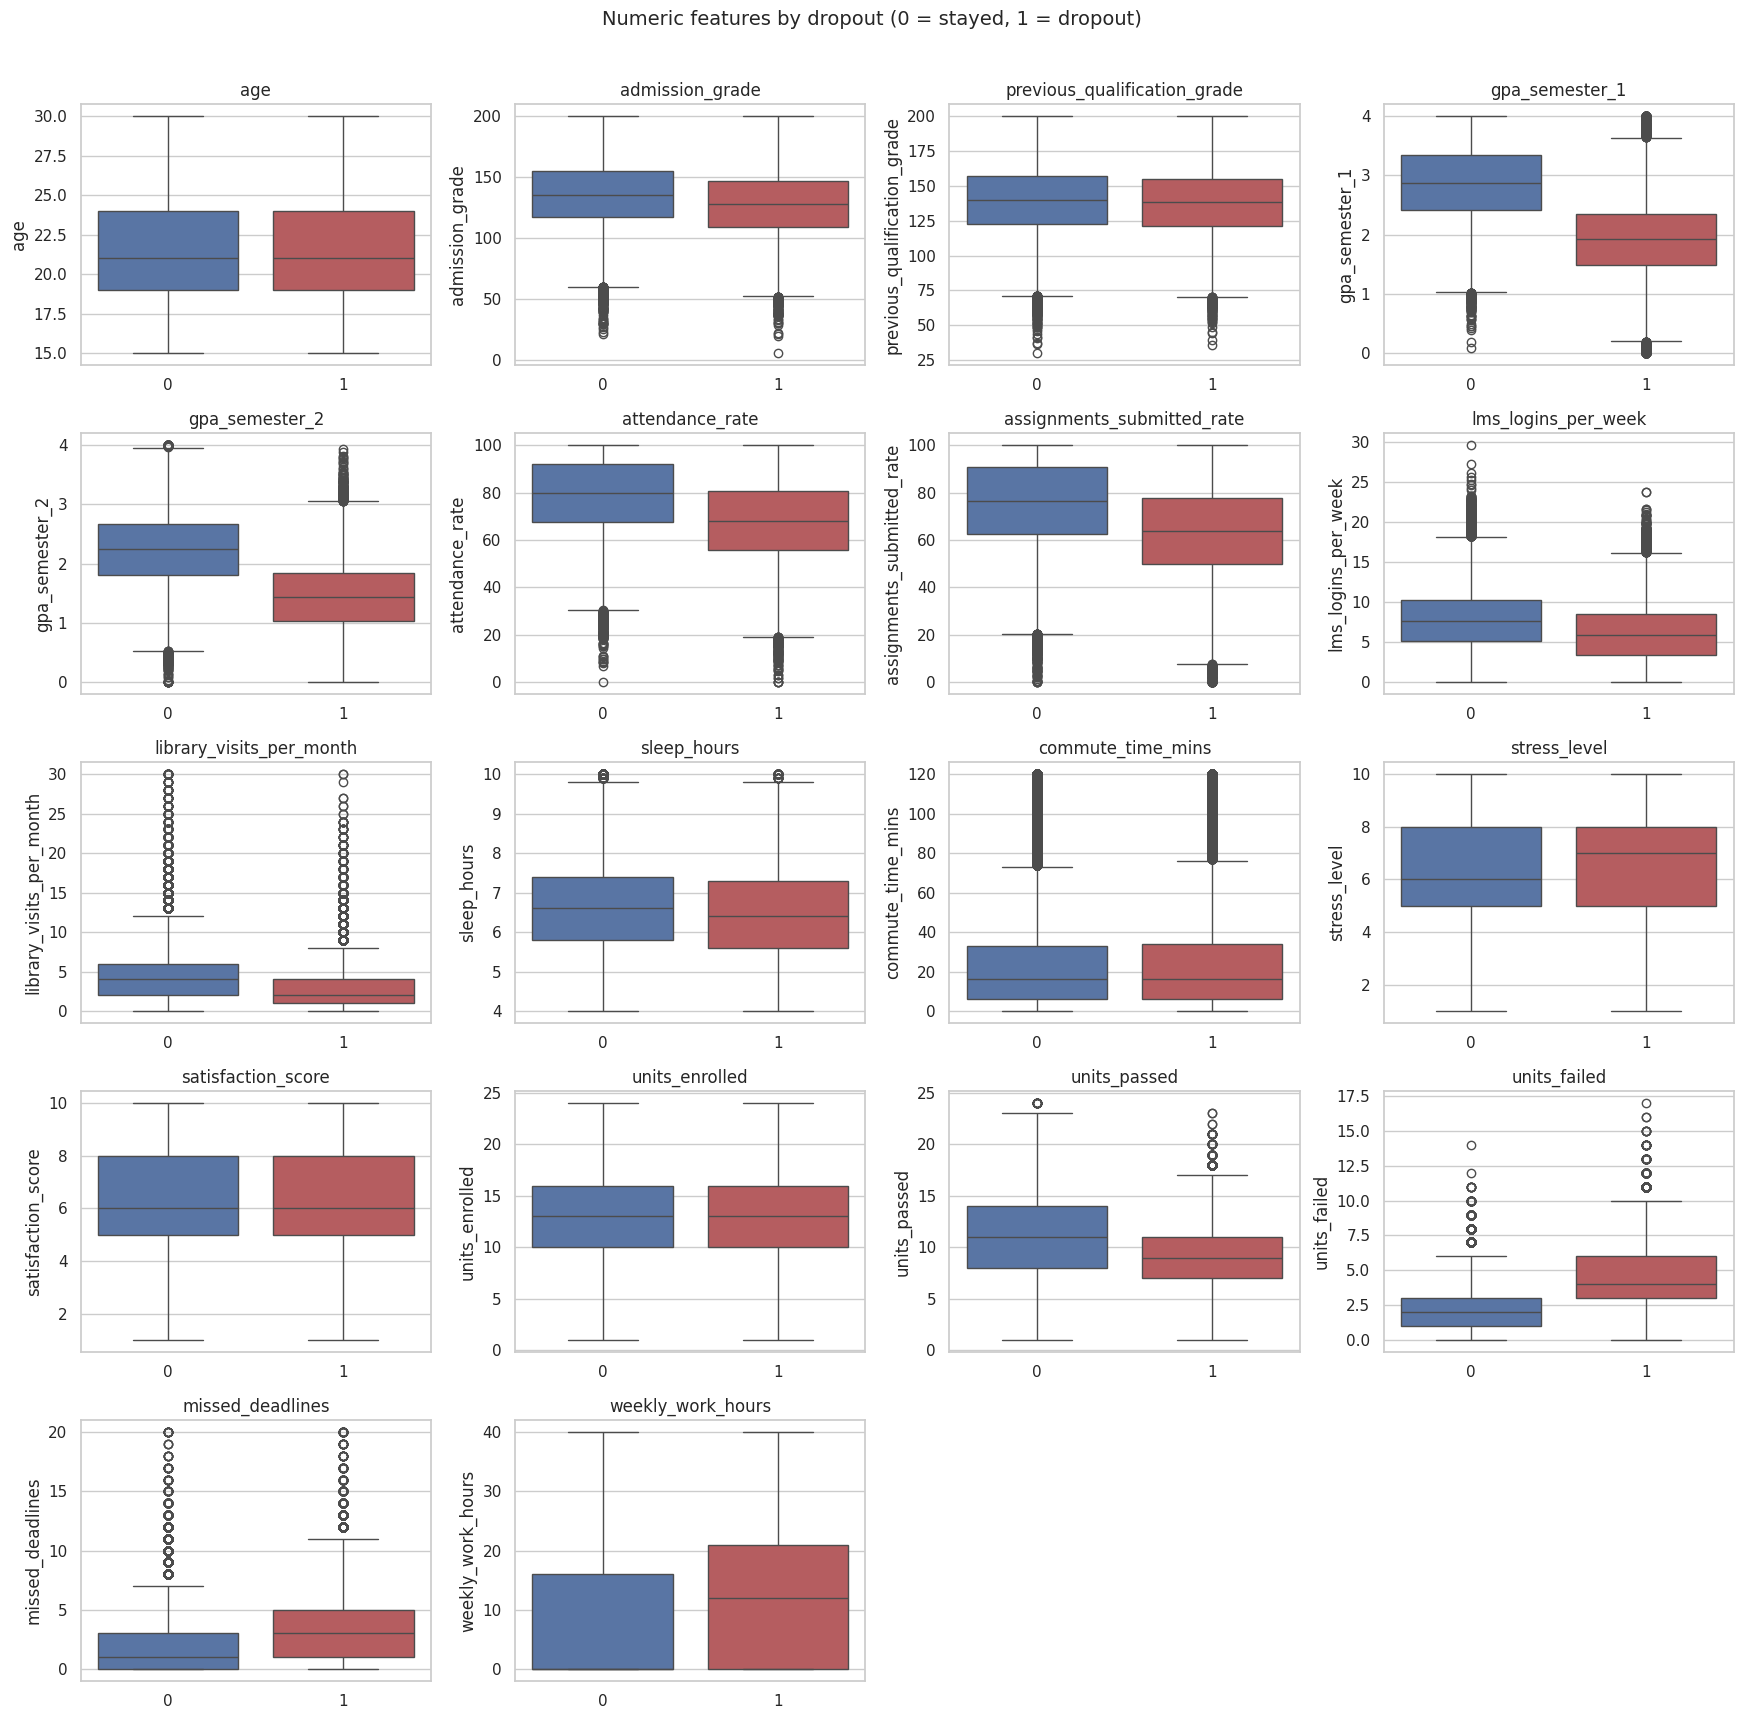

In [ ]:
fig, axes = make_grid(len(num_cols))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=viz, x=TARGET, y=c, orient="v", ax=ax,
                palette=["#4C72B0", "#C44E52"], hue=TARGET, legend=False)
    ax.set_title(c)
    ax.set_xlabel("")
fig.suptitle(f"Numeric features by {TARGET} (0 = stayed, 1 = dropout)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 4. Categorical features
Number of students in each category (top 10 values).

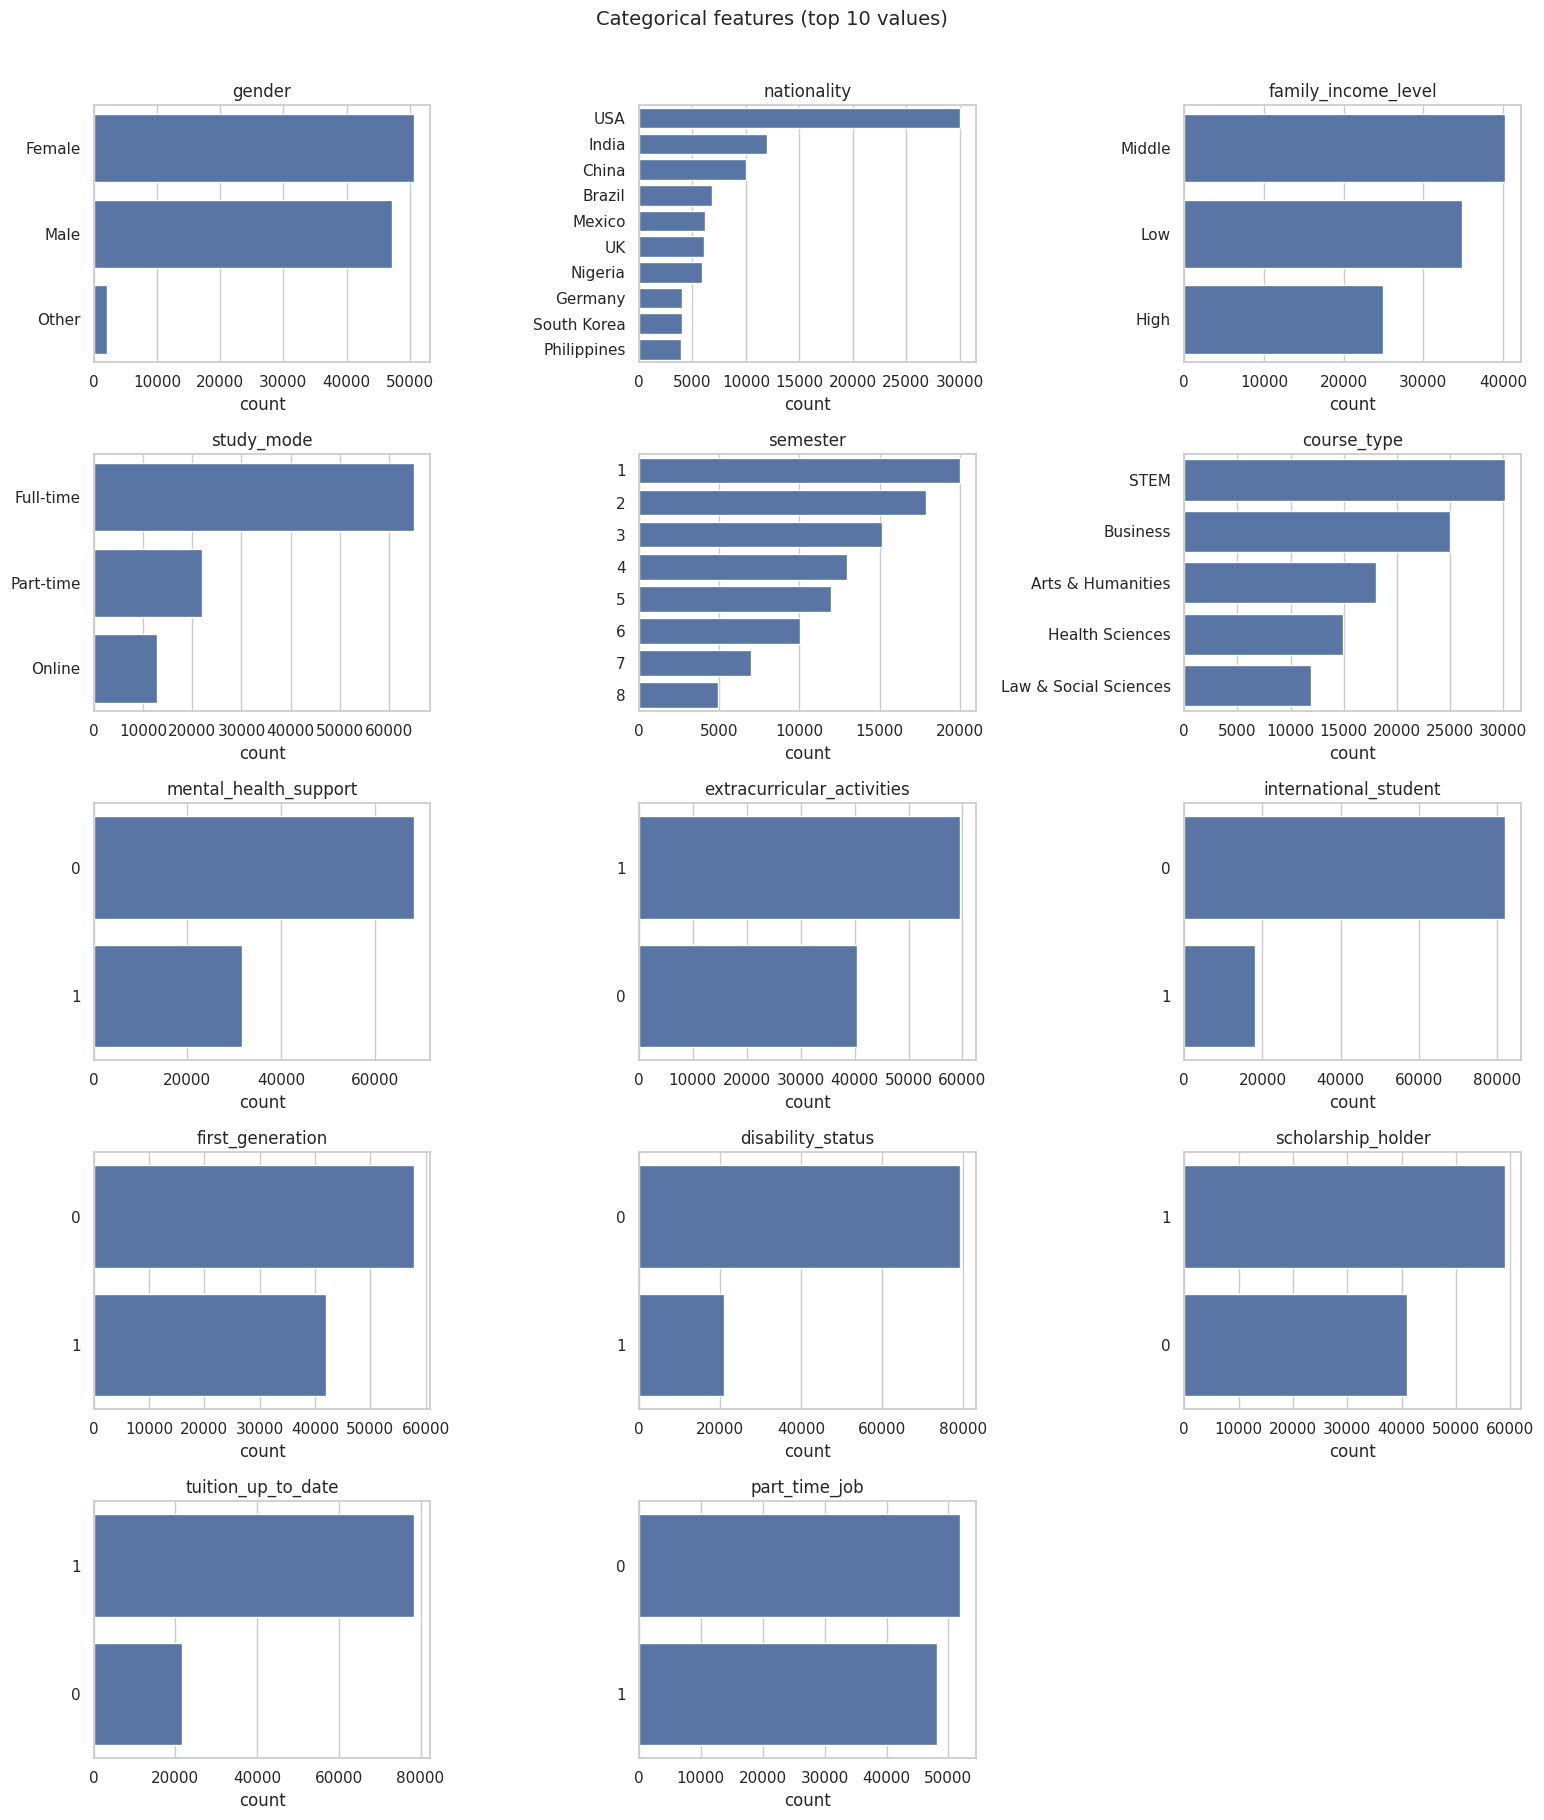

In [ ]:
fig, axes = make_grid(len(cat_cols), ncols=3, w=5.2, h=3.6)
for ax, c in zip(axes, cat_cols):
    order = top_cats(c)
    sns.countplot(data=viz[viz[c].isin(order)], y=c, order=order, ax=ax, color="#4C72B0")
    ax.set_title(c)
    ax.set_ylabel("")
fig.suptitle("Categorical features (top 10 values)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 5. Dropout rate by category
Dropout rate for each category. The dashed line is the overall rate.

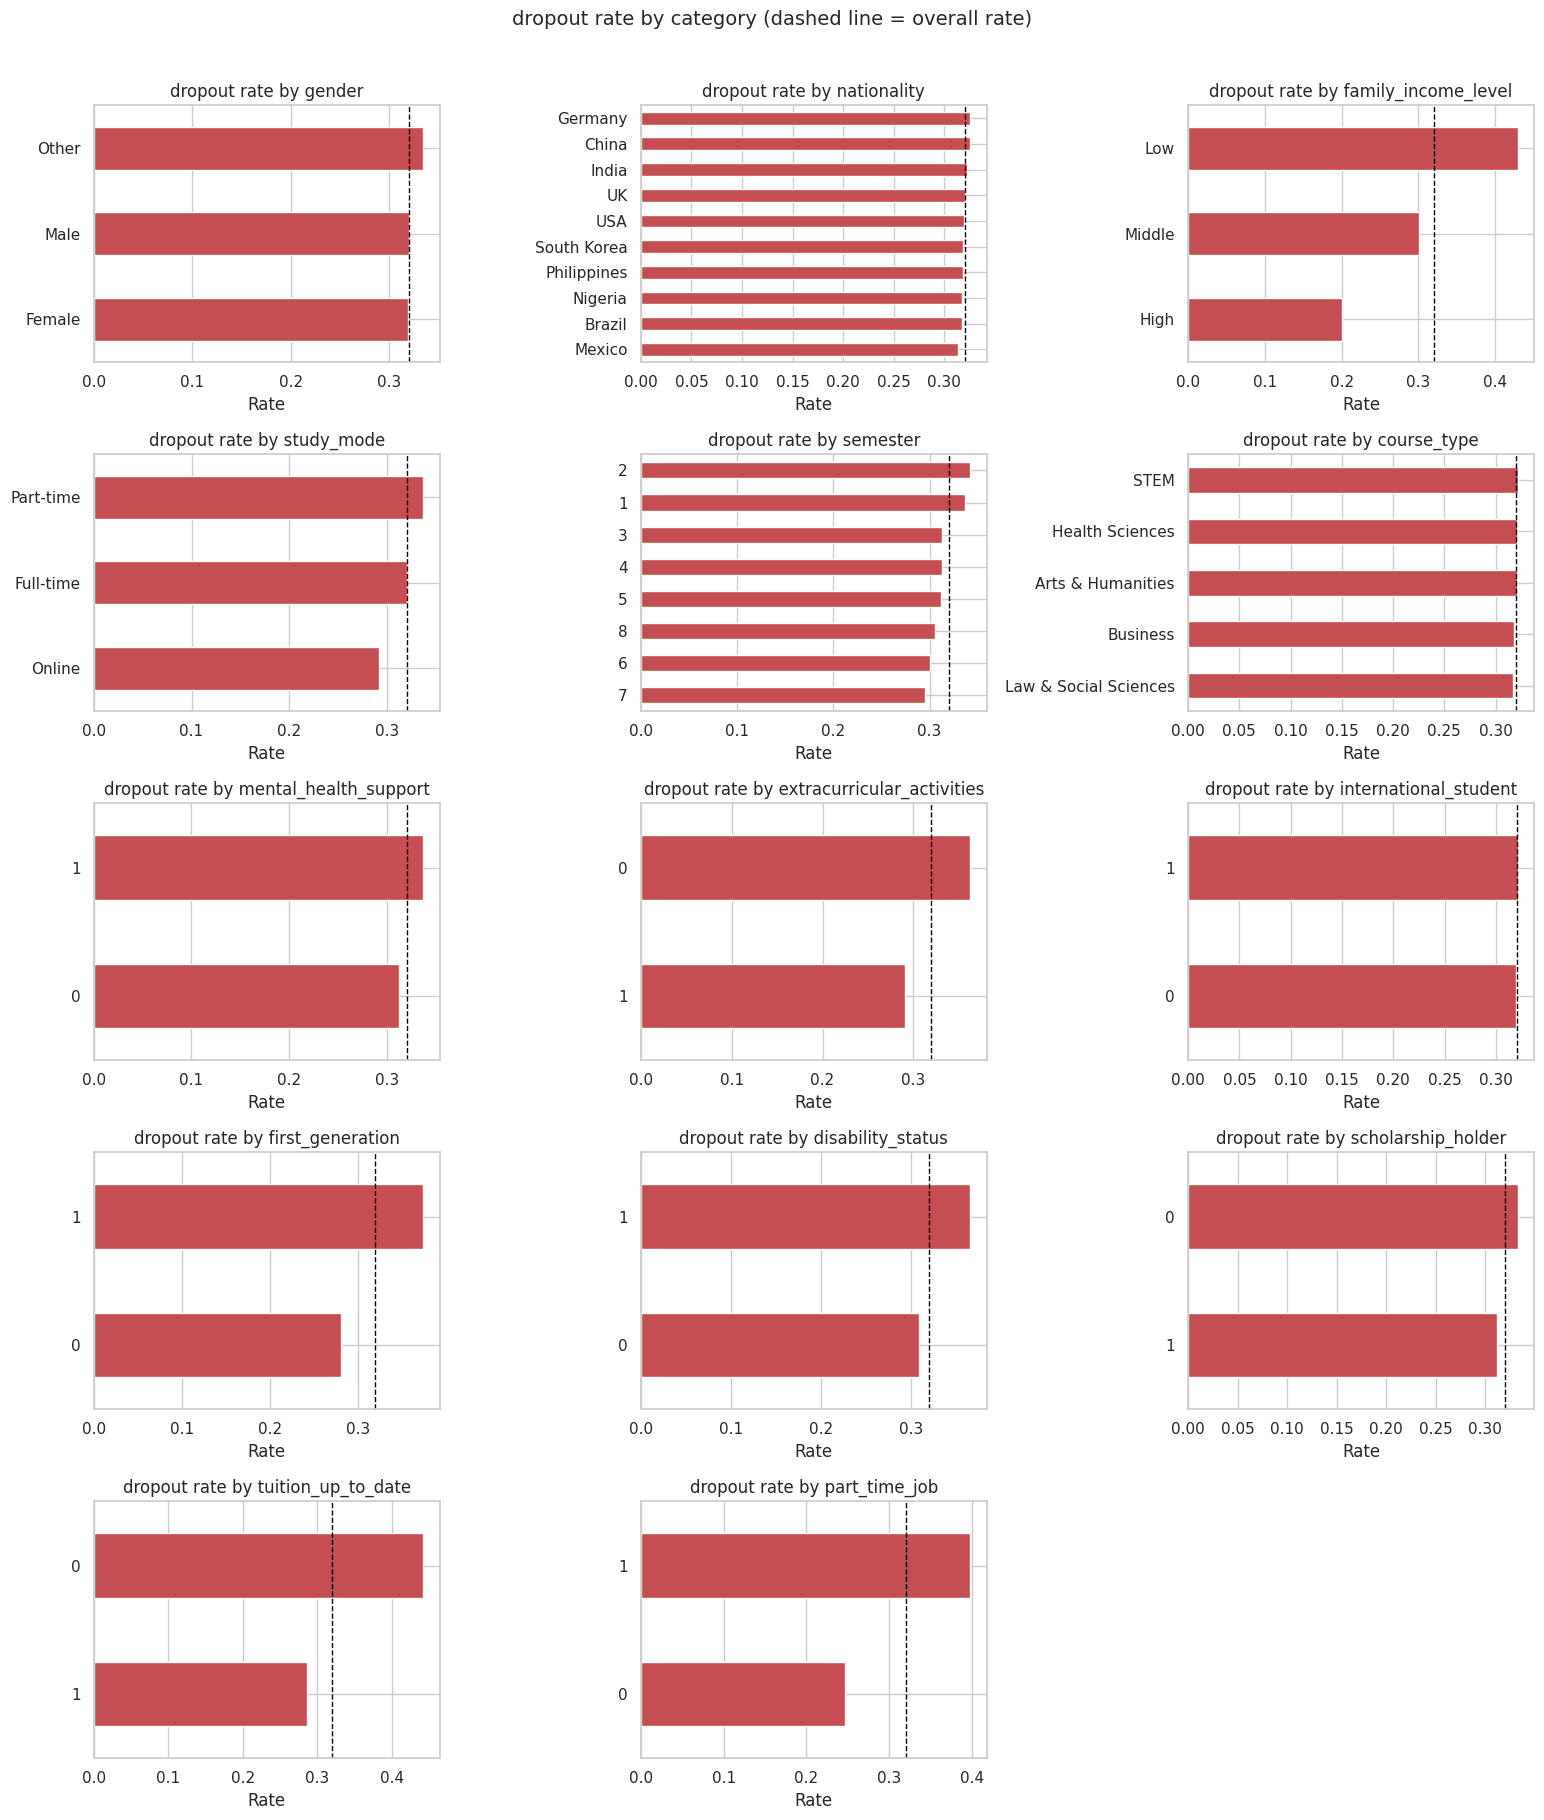

In [ ]:
fig, axes = make_grid(len(cat_cols), ncols=3, w=5.2, h=3.6)
for ax, c in zip(axes, cat_cols):
    sub = viz[viz[c].isin(top_cats(c))]
    rate = sub.groupby(c)[TARGET].mean().sort_values()
    rate.plot(kind="barh", ax=ax, color="#C44E52")
    ax.axvline(overall_rate, color="black", ls="--", lw=1)
    ax.set_title(f"{TARGET} rate by {c}")
    ax.set_xlabel("Rate")
    ax.set_ylabel("")
fig.suptitle(f"{TARGET} rate by category (dashed line = overall rate)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
for c in ["family_income_level", "tuition_up_to_date", "part_time_job", "first_generation"]:
    print(viz.groupby(c)[TARGET].agg(dropout_rate="mean", students="count").round(3))
    print()

                     dropout_rate  students
family_income_level                        
High                        0.200     24978
Low                         0.429     34809
Middle                      0.300     40213

                    dropout_rate  students
tuition_up_to_date                        
0                          0.442     21514
1                          0.287     78486

               dropout_rate  students
part_time_job                        
0                     0.247     51808
1                     0.398     48192

                  dropout_rate  students
first_generation                        
0                        0.281     57987
1                        0.374     42013



### 6. Correlations
Correlation heatmap between numeric features and the target.

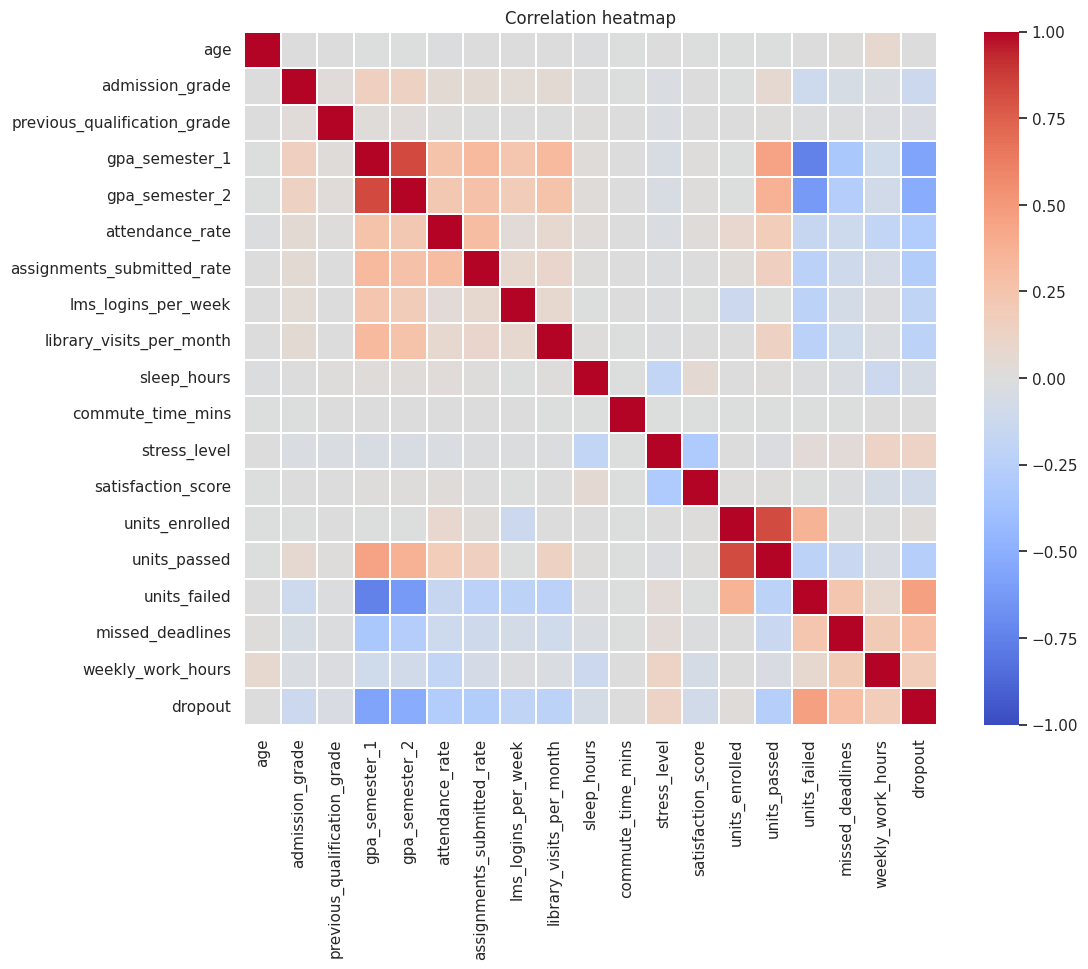

In [ ]:
corr = viz[num_cols + [TARGET]].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.3, square=True)
plt.title("Correlation heatmap")
plt.show()

**Top 10 features most correlated with dropout**

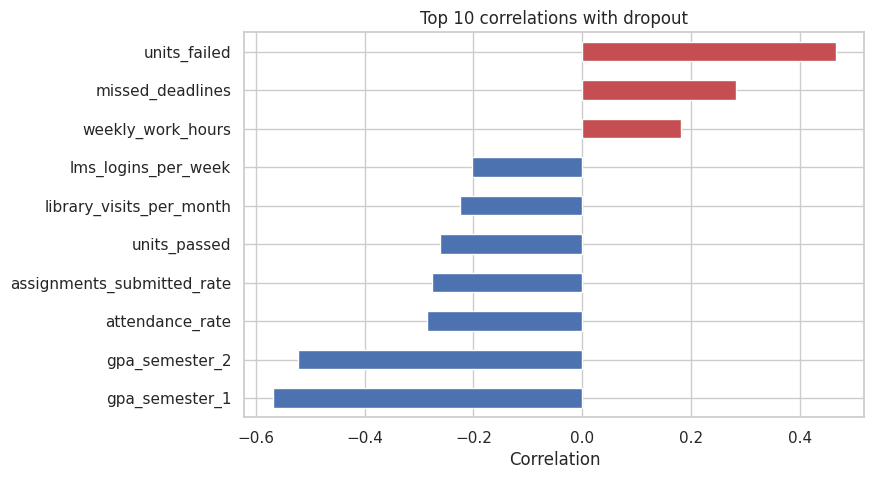

In [ ]:
top_corr = (corr[TARGET].drop(TARGET)
            .sort_values(key=abs, ascending=False).head(10)
            .sort_values())

plt.figure(figsize=(8, 5))
top_corr.plot(kind="barh", color=["#C44E52" if v > 0 else "#4C72B0" for v in top_corr])
plt.title(f"Top 10 correlations with {TARGET}")
plt.xlabel("Correlation")
plt.show()

### 7. Combined financial factors
Do low income and unpaid tuition add up? Dropout rate for each combination.

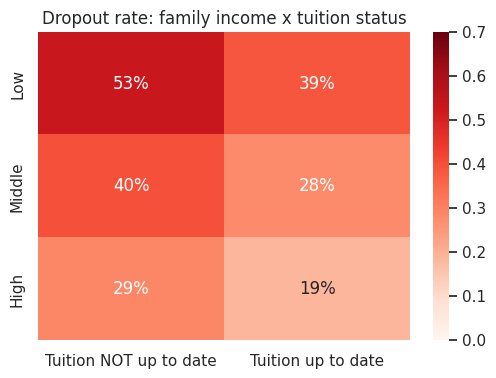

In [ ]:
pivot = (viz.groupby(["family_income_level", "tuition_up_to_date"])[TARGET]
            .mean().unstack().loc[["Low", "Middle", "High"]])
pivot.columns = ["Tuition NOT up to date", "Tuition up to date"]

plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Reds", vmin=0, vmax=0.7)
plt.title("Dropout rate: family income x tuition status")
plt.ylabel("")
plt.show()

### Does the number of work hours matter?
`weekly_work_hours` is 0 for every student without a job, so we look only at students who work and compare dropout rates across hour ranges against the no-job baseline.

In [ ]:
# Among students with a job: does the number of hours matter?
workers = viz[viz["part_time_job"] == 1]
work_bins = pd.cut(workers["weekly_work_hours"], bins=[0, 10, 15, 20, 25, 40])

print(workers.groupby(work_bins, observed=True)[TARGET]
             .agg(students="count", dropout_rate="mean").round(3))
print("\nNo-job baseline:", round(viz[viz["part_time_job"] == 0][TARGET].mean(), 3))

                   students  dropout_rate
weekly_work_hours                        
(0, 10]                6750         0.317
(10, 15]              10623         0.357
(15, 20]              13300         0.391
(20, 25]              10546         0.446
(25, 40]               6973         0.482

No-job baseline: 0.247


### Key Insights

#### Findings
- **Academics are the strongest signal:** GPA in both semesters (correlation about -0.57 and -0.52) and `units_failed` (about +0.47).
- **Money:** low income + unpaid tuition reaches 53% dropout vs 19% for high income + paid tuition. That group is 10% of students but about 17% of dropouts.
- **Work:** dropout is 39.8% with a job vs 24.7% without, and rises with hours: 31.7% (5-10 h) to 48.2% (25-40 h).
- **Background:** first-generation students drop out more (37.4% vs 28.1%). Gender, nationality, course type and international status show no real difference.

#### Cautions
- Correlation is not causation (for example `mental_health_support` likely reflects who receives it).
- Redundant features: GPA sem 1 vs 2, `units_enrolled` vs `units_passed`, `weekly_work_hours` vs `part_time_job`.



# Data Cleaning

## Duplicates Check

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["person_id"].duplicated().sum())

Duplicate rows: 0
Duplicate IDs: 0


## Rename columns

In [ ]:
df = df.rename(
    columns={"person_id": "student_id"}
)

## Unique values per column

In [ ]:
df.nunique()

,0
student_id,100000
age,16
gender,3
nationality,15
first_generation,2
disability_status,2
family_income_level,3
scholarship_holder,2
tuition_up_to_date,2
part_time_job,2


## Value counts per column

In [ ]:
for col in df.columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())


Column: student_id
student_id
1         1
2         1
3         1
4         1
5         1
         ..
99996     1
99997     1
99998     1
99999     1
100000    1
Name: count, Length: 100000, dtype: int64

Column: age
age
21    11514
22    11183
20    10364
23    10326
19     8878
24     8552
25     6904
18     6862
17     5005
26     4949
15     4406
16     3347
27     3316
28     2068
29     1177
30     1149
Name: count, dtype: int64

Column: gender
gender
Female    50731
Male      47224
Other      2045
Name: count, dtype: int64

Column: nationality
nationality
USA            29979
India          11994
China          10013
Brazil          6873
Mexico          6149
UK              6050
Nigeria         5921
Germany         4072
South Korea     4060
Philippines     3956
Pakistan        3030
Indonesia       2982
Egypt           1985
Canada          1967
Australia        969
Name: count, dtype: int64

Column: first_generation
first_generation
0    57987
1    42013
Name: count, dtype: int6

## Convert data types

In [ ]:
df["student_id"] = df["student_id"].astype("string")

## Trim extra spaces

In [ ]:
text_cols = [
    "gender", "nationality", "family_income_level",
    "course_type", "study_mode"
]

# strip() with proof: count how many values actually changed
before = df[text_cols].copy()
df[text_cols] = df[text_cols].apply(
    lambda col: col.str.strip())

changed = (before.ne(df[text_cols]) & before.notna()).sum()
print("Values changed by strip(), per column:")
print(changed.to_string())
print("Total changed:", int(changed.sum()))


Values changed by strip(), per column:
gender                 0
nationality            0
family_income_level    0
course_type            0
study_mode             0
Total changed: 0


## Impossible values

In [ ]:
# Impossible values: rows outside the allowed range of each column
limits = {
    "age": (10, 100),
    "gpa_semester_1": (0, 4), "gpa_semester_2": (0, 4),
    "attendance_rate": (0, 100), "assignments_submitted_rate": (0, 100),
    "admission_grade": (0, 200), "previous_qualification_grade": (0, 200),
    "sleep_hours": (0, 24), "commute_time_mins": (0, 1440),
    "stress_level": (1, 10), "satisfaction_score": (1, 10),
    "weekly_work_hours": (0, 168),
    "lms_logins_per_week": (0, float("inf")),
    "library_visits_per_month": (0, float("inf")),
    "missed_deadlines": (0, float("inf")),
    "units_enrolled": (0, float("inf")),
    "units_passed": (0, float("inf")),
    "units_failed": (0, float("inf")),
}
rows = []
for col, (lo, hi) in limits.items():
    if col in df.columns:
        bad = int(((df[col] < lo) | (df[col] > hi)).sum())
        rows.append({"column": col, "allowed": f"{lo} to {hi}", "out_of_range": bad})
range_check = pd.DataFrame(rows)

# Logic check: passed + failed units cannot exceed enrolled units
bad_units = int((df["units_passed"] + df["units_failed"] > df["units_enrolled"]).sum())

print("\nImpossible values:")
print(range_check.to_string(index=False))
print("Rows where passed + failed > enrolled:", bad_units)
print("Status:", "PASS" if range_check["out_of_range"].sum() == 0 and bad_units == 0 else "CHECK THE ROWS ABOVE")



Impossible values:
                      column   allowed  out_of_range
                         age 10 to 100             0
              gpa_semester_1    0 to 4             0
              gpa_semester_2    0 to 4             0
             attendance_rate  0 to 100             0
  assignments_submitted_rate  0 to 100             0
             admission_grade  0 to 200             0
previous_qualification_grade  0 to 200             0
                 sleep_hours   0 to 24             0
           commute_time_mins 0 to 1440             0
                stress_level   1 to 10             0
          satisfaction_score   1 to 10             0
           weekly_work_hours  0 to 168             0
         lms_logins_per_week  0 to inf             0
    library_visits_per_month  0 to inf             0
            missed_deadlines  0 to inf             0
              units_enrolled  0 to inf             0
                units_passed  0 to inf             0
                units_fail

In [ ]:
df.to_csv("student_dropout_risk_2026_cleaned.csv",index=False)
print("Final shape:", df.shape)

Final shape: (100000, 34)


## Save the cleaned data

In [ ]:
# Save the cleaned data to a new CSV and check the file
from pathlib import Path

out_file = Path("/content/drive/MyDrive/Tuwaiq/data/student_dropout_risk_2026_cleaned.csv")
df.to_csv(out_file, index=False)

saved = pd.read_csv(out_file)
print("\nSaved:", out_file)
print("Final shape:", df.shape, "| Reloaded shape:", saved.shape)


Saved: /content/drive/MyDrive/Tuwaiq/data/student_dropout_risk_2026_cleaned.csv
Final shape: (100000, 34) | Reloaded shape: (100000, 34)


# Dashboard (Gradio)

## Install Gradio

In [ ]:
%pip install gradio

## Build and launch the dashboard

In [ ]:
import pandas as pd
import gradio as gr
import matplotlib.pyplot as plt

if "demo" in globals():
    demo.close()


def finish_chart(fig):
    fig.tight_layout()
    plt.close(fig)
    return fig


def create_dropout_chart(data):
    counts = [
        int((data["dropout"] == 0).sum()),
        int((data["dropout"] == 1).sum()),
        int(data["dropout"].isna().sum())
    ]

    fig, ax = plt.subplots(figsize=(7, 4))

    bars = ax.bar(
        ["0", "1", "Missing"],
        counts,
        color=["#2563eb", "#f97316", "#94a3b8"]
    )

    ax.bar_label(bars, padding=3)
    ax.set_title("Dropout Status Distribution")
    ax.set_xlabel("Dropout Code")
    ax.set_ylabel("Number of Records")
    ax.set_ylim(0, max(max(counts) * 1.15, 1))

    return finish_chart(fig)


def create_income_chart(data):
    known = data[data["dropout"].isin([0, 1])]

    rates = (
        known.groupby("family_income_level")["dropout"]
        .mean()
        .mul(100)
    )

    preferred_order = ["Low", "Middle", "High"]
    order = [level for level in preferred_order if level in rates.index]
    order += [level for level in rates.index if level not in order]
    rates = rates.reindex(order)

    fig, ax = plt.subplots(figsize=(7, 4))

    if rates.empty:
        ax.text(
            0.5, 0.5,
            "No matching data",
            ha="center",
            transform=ax.transAxes
        )
    else:
        bars = ax.bar(
            rates.index.astype(str),
            rates.values,
            color="#0d9488"
        )
        ax.bar_label(bars, fmt="%.1f%%", padding=3)

    ax.set_title("Code 1 Rate by Family Income")
    ax.set_xlabel("Family Income Level")
    ax.set_ylabel("Code 1 Rate (%)")
    ax.set_ylim(0, 110)

    return finish_chart(fig)


def create_comparison_chart(data, column, title, ylabel):
    groups = [
        data.loc[data["dropout"] == code, column].dropna()
        for code in [0, 1]
    ]

    fig, ax = plt.subplots(figsize=(7, 4))

    if all(group.empty for group in groups):
        ax.text(
            0.5, 0.5,
            "No matching data",
            ha="center",
            transform=ax.transAxes
        )
    else:
        boxes = ax.boxplot(
            groups,
            patch_artist=True,
            showfliers=False
        )

        for box, color in zip(
            boxes["boxes"],
            ["#93c5fd", "#fdba74"]
        ):
            box.set_facecolor(color)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["0", "1"])
    ax.set_title(title)
    ax.set_xlabel("Dropout Code")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.2)

    return finish_chart(fig)


ALL = "All"
INCOME_ORDER = ["Low", "Middle", "High"]
TUITION_VALUES = {"Paid": 1, "Unpaid": 0}
JOB_VALUES = {"Has a job": 1, "No job": 0}

gender_choices = [ALL] + df["gender"].dropna().unique().tolist()
income_choices = [ALL] + [x for x in INCOME_ORDER if x in set(df["family_income_level"].dropna())]
mode_choices = [ALL] + sorted(df["study_mode"].dropna().unique().tolist())
tuition_choices = [ALL] + list(TUITION_VALUES)
job_choices = [ALL] + list(JOB_VALUES)


def apply_filters(gender, income, mode, tuition, job):
    data = df
    if gender != ALL:
        data = data[data["gender"] == gender]
    if income != ALL:
        data = data[data["family_income_level"] == income]
    if mode != ALL:
        data = data[data["study_mode"] == mode]
    if tuition != ALL:
        data = data[data["tuition_up_to_date"] == TUITION_VALUES[tuition]]
    if job != ALL:
        data = data[data["part_time_job"] == JOB_VALUES[job]]
    return data


def update_dashboard(gender, income, mode, tuition, job):
    data = apply_filters(gender, income, mode, tuition, job)

    average = (
        round(data["age"].mean(), 1)
        if data["age"].notna().any()
        else None
    )

    return (
        len(data),
        average,
        create_dropout_chart(data),
        create_income_chart(data),
        create_comparison_chart(
            data,
            "attendance_rate",
            "Attendance by Dropout Status",
            "Attendance Rate"
        ),
        create_comparison_chart(
            data,
            "gpa_semester_2",
            "Semester 2 GPA by Dropout Status",
            "Semester 2 GPA"
        ),
        data.head(10)
    )


initial = update_dashboard(ALL, ALL, ALL, ALL, ALL)

with gr.Blocks() as demo:
    gr.Markdown("# Student Academic Performance Dashboard")
    gr.Markdown(
        "Explore dropout status, family income, attendance, "
        "and academic performance. "
        "Charts describe associations, not causes."
    )

    with gr.Sidebar(open=True):
        gr.Markdown("## About the Dataset")
        gr.Markdown(
            "Student demographic and academic records. "
            "Statistics and charts use all matching records. "
            "The table previews the first 10."
        )

        gr.Markdown("## Filters")

        gender_filter = gr.Dropdown(
            choices=gender_choices, value=ALL, label="Gender"
        )
        income_filter = gr.Dropdown(
            choices=income_choices, value=ALL, label="Family income"
        )
        mode_filter = gr.Dropdown(
            choices=mode_choices, value=ALL, label="Study mode"
        )
        tuition_filter = gr.Dropdown(
            choices=tuition_choices, value=ALL, label="Tuition status"
        )
        job_filter = gr.Dropdown(
            choices=job_choices, value=ALL, label="Part-time job"
        )

        gr.Markdown(
            "Dropout codes are shown as recorded. "
            "Missing status values are excluded from rate calculations."
        )

    with gr.Row():
        total_records = gr.Number(
            value=initial[0],
            label="Total Records",
            interactive=False
        )

        gr.Number(
            value=df.shape[1],
            label="Total Columns",
            interactive=False
        )

        average_age = gr.Number(
            value=initial[1],
            label="Average Age",
            interactive=False
        )

    with gr.Row():
        dropout_plot = gr.Plot(
            value=initial[2],
            label="Dropout Status"
        )

        income_plot = gr.Plot(
            value=initial[3],
            label="Family Income"
        )

    with gr.Row():
        attendance_plot = gr.Plot(
            value=initial[4],
            label="Attendance"
        )

        gpa_plot = gr.Plot(
            value=initial[5],
            label="Academic Performance"
        )

    data_table = gr.Dataframe(
        value=initial[6],
        label="Student Data Preview",
        interactive=False
    )

    filters = [gender_filter, income_filter, mode_filter, tuition_filter, job_filter]

    gr.on(
        triggers=[f.change for f in filters],
        fn=update_dashboard,
        inputs=filters,
        outputs=[
            total_records,
            average_age,
            dropout_plot,
            income_plot,
            attendance_plot,
            gpa_plot,
            data_table
        ]
    )

demo.launch(
    theme=gr.themes.Soft(
        primary_hue="blue",
        secondary_hue="cyan",
        neutral_hue="slate"
    )
)

Closing server running on port: 7860
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2b3c9bcc455529d94c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
print(df.columns.tolist())

['student_id', 'age', 'gender', 'nationality', 'first_generation', 'disability_status', 'family_income_level', 'scholarship_holder', 'tuition_up_to_date', 'part_time_job', 'weekly_work_hours', 'course_type', 'study_mode', 'semester', 'international_student', 'admission_grade', 'previous_qualification_grade', 'units_enrolled', 'units_passed', 'units_failed', 'gpa_semester_1', 'gpa_semester_2', 'attendance_rate', 'assignments_submitted_rate', 'library_visits_per_month', 'lms_logins_per_week', 'extracurricular_activities', 'missed_deadlines', 'stress_level', 'mental_health_support', 'satisfaction_score', 'commute_time_mins', 'sleep_hours', 'dropout']


In [ ]:
df["dropout"].value_counts(dropna=False)

In [ ]:
%%writefile requirements.txt
gradio==6.31.0
pandas
matplotlib

In [ ]:
%%writefile app.py
from pathlib import Path

import pandas as pd
import gradio as gr
import matplotlib.pyplot as plt

file_path = Path(__file__).resolve().parent / "student_dropout_risk_2026.csv"

df = pd.read_csv(file_path)


def create_dropout_chart(data):
    labels = ["0", "1", "Missing"]

    counts = [
        int((data["dropout"] == 0).sum()),
        int((data["dropout"] == 1).sum()),
        int(data["dropout"].isna().sum())
    ]

    fig, ax = plt.subplots(figsize=(7, 4))

    bars = ax.bar(
        labels,
        counts,
        color=["#2563eb", "#f97316", "#94a3b8"]
    )

    ax.bar_label(bars, padding=3)
    ax.set_title("Dropout Distribution")
    ax.set_xlabel("Dropout Code")
    ax.set_ylabel("Number of Records")
    ax.set_ylim(0, max(max(counts) * 1.15, 1))

    fig.tight_layout()
    plt.close(fig)

    return fig


def create_age_chart(data):
    fig, ax = plt.subplots(figsize=(7, 4))

    ax.hist(
        data["age"].dropna(),
        bins=10,
        color="#2563eb",
        edgecolor="white"
    )

    ax.set_title("Age Distribution")
    ax.set_xlabel("Age")
    ax.set_ylabel("Number of Records")

    fig.tight_layout()
    plt.close(fig)

    return fig


def filter_data(selected_gender):
    if selected_gender == "All":
        filtered_df = df
    else:
        filtered_df = df[df["gender"] == selected_gender]

    total = len(filtered_df)

    if filtered_df["age"].notna().any():
        average = round(filtered_df["age"].mean(), 1)
    else:
        average = None

    dropout_chart = create_dropout_chart(filtered_df)
    age_chart = create_age_chart(filtered_df)

    return (
        filtered_df.head(10),
        total,
        average,
        dropout_chart,
        age_chart
    )


with gr.Blocks() as demo:
    gr.Markdown("# Student Dropout Dashboard")
    gr.Markdown(
        "Use the filters to explore student records. "
        "Charts and statistics include all matching records. "
        "The table previews the first 10 matching records."
    )

    with gr.Sidebar(open=True):
        gr.Markdown("## About the Dataset")
        gr.Markdown(
            "Student records covering demographics, academic "
            "performance, attendance, and dropout status."
        )

        gr.Markdown("## Filters")

        gender_filter = gr.Dropdown(
            choices=["All"] + df["gender"].dropna().unique().tolist(),
            value="All",
            label="Select Gender"
        )

    with gr.Row():
        total_records = gr.Number(
            value=len(df),
            label="Total Records",
            interactive=False
        )

        gr.Number(
            value=df.shape[1],
            label="Total Columns",
            interactive=False
        )

        average_age = gr.Number(
            value=round(df["age"].mean(), 1),
            label="Average Age",
            interactive=False
        )

    with gr.Row():
        dropout_plot = gr.Plot(
            value=create_dropout_chart(df),
            label="Dropout Distribution"
        )

        age_plot = gr.Plot(
            value=create_age_chart(df),
            label="Age Distribution"
        )

    data_table = gr.Dataframe(
        value=df.head(10),
        label="Student Data Preview",
        interactive=False
    )

    gender_filter.change(
        fn=filter_data,
        inputs=gender_filter,
        outputs=[
            data_table,
            total_records,
            average_age,
            dropout_plot,
            age_plot
        ]
    )

demo.launch()

In [ ]:
import py_compile

py_compile.compile("app.py", doraise=True)
print("Syntax check passed.")

if "demo" in globals():
    demo.close()

%run app.py

In [ ]:
%%writefile README.md
# Student Dropout Dashboard

A Gradio dashboard for exploring student records.

## Features

- Gender filter
- Record and column counts
- Average age
- Dropout distribution chart
- Age distribution chart
- Preview of the first 10 matching records

Statistics and charts use all matching records.

## Required Files

- app.py
- requirements.txt
- student_dropout_risk_2026.csv

Place the CSV file in the same folder as app.py.

## Run Locally

Install the dependencies:

```bash
python -m pip install -r requirements.txt
```

Start the dashboard:

```bash
python app.py
```

Open the local URL printed in the terminal.

## Data Notes

Use the final cleaned dataset for submission.
If its filename changes, update file_path in app.py.

Dropout codes are displayed as 0 and 1.
Confirm their meaning using the original dataset documentation.

## Dataset Source

Add the original Kaggle or Hugging Face dataset URL before submission.

In [ ]:
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

file_names = [
    "app.py",
    "requirements.txt",
    "README.md"
]

with ZipFile("gradio_dashboard.zip", "w", ZIP_DEFLATED) as archive:
    for file_name in file_names:
        archive.write(file_name)

files.download("gradio_dashboard.zip")